# 电商交易分析学习记录

基础项目已完成。内容包括数据检查、清洗审计、月度趋势、国家和商品汇总，以及客户指标的 SQLite 核对。项目进度和复现步骤见 [README](README.md)，分阶段实践见 [学习进度](LEARNING_LOG.md)。

使用 Kaggle 的 E-Commerce Data CSV，原出处为 UCI 的 Online Retail。公开版展示汇总数据与图表。部分练习、复核和整理使用了 AI 协助。

## 1. 数据来源与字段

- Kaggle：https://www.kaggle.com/datasets/carrie1/ecommerce-data
- 原始说明：https://archive.ics.uci.edu/dataset/352/online+retail
- 时间范围与数据质量以本地检查为准。金额单位依来源说明为英镑。

|字段|含义|注意|
|---|---|---|
|InvoiceNo|订单/发票编号|可重复；C开头表示取消，需核对|
|StockCode|商品编号|不是股票代码；可能含字母|
|Description|商品描述|检查缺失及不一致|
|Quantity|本条明细的商品数量|负数、零值需要解释|
|InvoiceDate|交易时间|先保留原文，后续明确格式转换|
|UnitPrice|单件价格|不能直接把单价求和当销售额|
|CustomerID|客户编号|可能缺失；重复不等于重复记录|
|Country|客户所在国家|分组维度|

一行通常是一张订单中的一条商品明细。同一订单可有多行，同一客户可有多张订单。

## 2. 读取原始数据

在仓库根目录启动 Notebook，按 README 把 CSV 放在 `data/data.csv`。文件以 `cp1252` 读取，编号列使用字符串类型，便于保留含字母的标识。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

data_path = Path("data") / "data.csv"
if not data_path.is_file():
    raise FileNotFoundError("找不到 data/data.csv。请按 README 放置 CSV，并从仓库根目录运行 Notebook。")

raw = pd.read_csv(
    data_path,
    encoding="cp1252",
    dtype={"InvoiceNo": "string", "StockCode": "string", "CustomerID": "string"},
)
df = raw.copy()
print("数据规模：", df.shape)

数据规模： (541909, 8)


## 3. 记录单位与数据质量

检查字段类型、缺失、整行重复与非正数量和单价。对发票和客户分别计数时，用 `nunique()` 统计不同值，默认排除缺失值。原始发票数包含带取消标记的发票。

In [2]:
print("字段类型：")
print(df.dtypes)
print("各列缺失数：")
print(df.isna().sum())
print("商品明细行数：", len(df))
print("不同发票数：", df["InvoiceNo"].nunique())
print("不同非缺失客户数：", df["CustomerID"].nunique())
print("完全重复行数：", df.duplicated().sum())
print("数量非正的明细数：", (df["Quantity"] <= 0).sum())
print("单价非正的明细数：", (df["UnitPrice"] <= 0).sum())

字段类型：
InvoiceNo      string[python]
StockCode      string[python]
Description            object
Quantity                int64
InvoiceDate            object
UnitPrice             float64
CustomerID     string[python]
Country                object
dtype: object
各列缺失数：
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
商品明细行数： 541909
不同发票数： 25900
不同非缺失客户数： 4372


完全重复行数： 5268
数量非正的明细数： 10624
单价非正的明细数： 2517


### 数据质量小结

一行是一条商品明细。541,909 行对应 25,900 个不同发票号和 4,372 个非缺失客户编号。同一客户可能有多次购买，同一发票也可以有多行。

商品描述缺失 1,454 条，客户编号缺失 135,080 条。发现 5,268 条与此前行完全相同的记录。10,624 条明细数量非正，2,517 条单价非正，两类条件有重叠。

## 4. 清洗口径与审计

调查带取消标记、非正数量或非正价格的记录。对正向交易保留未标记取消、数量为正且单价为正的明细。客户编号缺失的明细仍可计入这一交易口径。

对完全一致的行保留首次出现，并审计行数和金额。相同行也可能来自业务过程，因此这一步是一条探索性规则。

`str.startswith("C", na=False)` 识别取消标记。用 `pd.crosstab` 交叉计数，检查取消标记与非正数量如何重叠。

In [3]:
is_cancelled = df["InvoiceNo"].str.startswith("C", na=False)

print("取消记录明细数：", is_cancelled.sum())
print(pd.crosstab(
    is_cancelled,
    df["Quantity"] <= 0,
    rownames=["取消记录"],
    colnames=["数量非正"],
))

取消记录明细数： 9288
数量非正    False  True 
取消记录                
False  531285   1336
True        0   9288


In [4]:
# ~ 对布尔条件取反
non_cancel_nonpositive = df.loc[
    (~is_cancelled) & (df["Quantity"] <= 0)
].copy()

以下用汇总计数检查无取消标记的非正数量记录。业务原因仍需额外来源解释。

In [5]:
print("该子集总行数：", len(non_cancel_nonpositive))

print("其中单价非正的行数：",
      (non_cancel_nonpositive["UnitPrice"] <= 0).sum())

print("其中客户编号缺失的行数：",
      non_cancel_nonpositive["CustomerID"].isna().sum())

# 另外检查：有正数量，却没有正价格的记录
positive_qty_nonpositive_price = df[
    (df["Quantity"] > 0) & (df["UnitPrice"] <= 0)
]

print("数量正、单价非正的行数：",
      len(positive_qty_nonpositive_price))

该子集总行数： 1336
其中单价非正的行数： 1336
其中客户编号缺失的行数： 1336
数量正、单价非正的行数： 1181


In [6]:
# 分步骤筛选，保留原始df，方便核对每一步排除了多少行
non_cancelled = df[
    ~df["InvoiceNo"].str.startswith("C", na=False)
].copy()

positive_quantity = non_cancelled[
    non_cancelled["Quantity"] > 0
].copy()

sales_candidates = positive_quantity[
    positive_quantity["UnitPrice"] > 0
].copy()

# 清洗审计：记录每一步剩余行数
audit = pd.DataFrame({
    "步骤": [
        "原始明细",
        "排除取消记录后",
        "再排除非正数量后",
        "再排除非正价格后"
    ],
    "剩余行数": [
        len(df),
        len(non_cancelled),
        len(positive_quantity),
        len(sales_candidates)
    ]
})

print(audit.to_string(index=False))

print("候选记录中的完全重复行数：",
      sales_candidates.duplicated().sum())

      步骤   剩余行数
    原始明细 541909
 排除取消记录后 532621
再排除非正数量后 531285
再排除非正价格后 530104


候选记录中的完全重复行数： 5226


In [7]:
# 全部列相同才去重，默认保留首次出现
sales = sales_candidates.drop_duplicates().copy()

# 明细金额 = 数量 × 单价
sales["LineAmount"] = sales["Quantity"] * sales["UnitPrice"]

# 比较去重对行数和金额的影响
amount_before = (
    sales_candidates["Quantity"] * sales_candidates["UnitPrice"]
).sum()

amount_after = sales["LineAmount"].sum()

print("去重前行数：", len(sales_candidates))
print("去重后行数：", len(sales))
print("剩余完全重复行数：", sales.duplicated().sum())

print("去重前金额：", round(amount_before, 2))
print("去重后金额：", round(amount_after, 2))
print("金额减少：", round(amount_before - amount_after, 2))

去重前行数： 530104
去重后行数： 524878


剩余完全重复行数： 0
去重前金额： 10666684.54
去重后金额： 10642110.8
金额减少： 24573.74


.drop_duplicates()：按全部列判断重复，默认保留首次，返回新表。
.copy()：建立分析副本，原候选表不变。
LineAmount：每条明细的金额，单位为英镑。
round(..., 2)：显示时保留两位小数。

## 5. 销售与订单分析

先验证交易时间的解析结果，再按月汇总正向交易金额、不同发票数和平均每单金额。每月发票数在该月内去重。

In [8]:
# 原始格式示例：12/1/2010 8:26，表示2010年12月1日
sales["InvoiceDate"] = pd.to_datetime(
    sales["InvoiceDate"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

print("日期类型：", sales["InvoiceDate"].dtype)
print("日期缺失或转换失败数：", sales["InvoiceDate"].isna().sum())
print("最早交易：", sales["InvoiceDate"].min())
print("最晚交易：", sales["InvoiceDate"].max())

日期类型： datetime64[ns]
日期缺失或转换失败数： 0
最早交易： 2010-12-01 08:26:00
最晚交易： 2011-12-09 12:50:00


`pd.to_datetime` 用 `%m/%d/%Y %H:%M` 解析日期和时间。`errors="coerce"` 将解析失败的值标成 `NaT`，便于计数核对。

In [9]:
# 提取“年-月”，同一年同一月归为一组
sales["Month"] = sales["InvoiceDate"].dt.to_period("M")

# 对不同列使用不同统计方法，并直接给结果列命名
monthly = sales.groupby("Month").agg(
    transaction_amount=("LineAmount", "sum"),
    order_count=("InvoiceNo", "nunique")
)

monthly["average_order_value"] = (
    monthly["transaction_amount"] / monthly["order_count"]
)

print(monthly.round(2))

         transaction_amount  order_count  average_order_value
Month                                                        
2010-12           821452.73         1559               526.91
2011-01           689811.61         1086               635.19
2011-02           522545.56         1100               475.04
2011-03           716215.26         1454               492.58
2011-04           536968.49         1246               430.95
2011-05           769296.61         1681               457.64
2011-06           760547.01         1533               496.12
2011-07           718076.12         1475               486.83
2011-08           757841.38         1361               556.83
2011-09          1056435.19         1837               575.09
2011-10          1151263.73         2040               564.34
2011-11          1503866.78         2769               543.11
2011-12           637790.33          819               778.74


`dt.to_period("M")` 提取日期所属的月份。命名聚合中的 `order_count=("InvoiceNo", "nunique")` 统计每组不同发票号的数量。

### 月度交易金额与订单数趋势

交易金额按清洗后的正向交易明细汇总，订单数按每月不同的 `InvoiceNo` 计数。2011 年 12 月只覆盖到 9 日 12:50，`monthly` 中保留该月数据，趋势图绘制 2010 年 12 月至 2011 年 11 月。

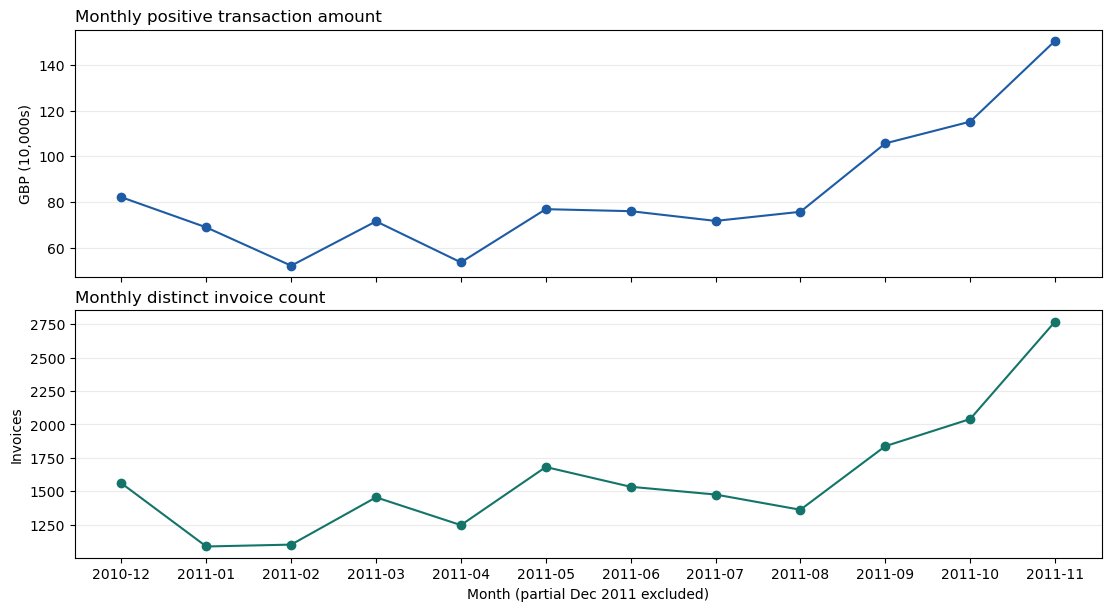

In [10]:
# monthly 的索引就是月份；pd.Period(..., freq="M") 表示一个月。
# .loc[条件] 只取满足条件的行，.sort_index() 再按月份从早到晚排序。
# 2011 年 12 月只到 9 日中午，留在 monthly，绘图数据只取它之前的月份。
trend_monthly = monthly.loc[monthly.index < pd.Period("2011-12", freq="M")].sort_index()
# 把月份索引转成 "2011-01" 这样的文字，作为横轴标签。
month_labels = trend_monthly.index.astype(str)

# 在 with 代码块里临时设置图表字体，退出后恢复默认设置。
with plt.rc_context({"font.family": "DejaVu Sans"}):
    # subplots(2, 1) 建立 2 行 1 列；fig 是整张图，axes 里放两张子图。
    # sharex=True 共享月份轴；figsize 的单位是英寸，constrained 自动安排间距。
    fig, axes = plt.subplots(2, 1, sharex=True, figsize=(11, 6), layout="constrained")

    # 第一张子图：plot(横轴, 纵轴) 画折线。
    # 金额原来以英镑计，除以 10_000 后用万英镑显示。marker="o" 给每月加圆点。
    axes[0].plot(
        month_labels, trend_monthly["transaction_amount"] / 10_000,
        marker="o", color="#1d5ba5",
    )
    # 标题靠左，纵轴注明换算后的单位。
    axes[0].set_title("Monthly positive transaction amount", loc="left")
    axes[0].set_ylabel("GBP (10,000s)")

    # 第二张子图沿用同一组月份，纵轴直接使用已按发票编号去重的订单数。
    axes[1].plot(
        month_labels, trend_monthly["order_count"],
        marker="o", color="#13756a",
    )
    axes[1].set_title("Monthly distinct invoice count", loc="left")
    axes[1].set_ylabel("Invoices")
    axes[1].set_xlabel("Month (partial Dec 2011 excluded)")

    # 依次给两张子图加横向网格线，alpha 控制透明度，网格线放在数据后面。
    for ax in axes:
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)

    # 显示已经画好的两张子图。
    plt.show()

2011 年 10 月到 11 月，交易金额从 £1,151,263.73 增至 £1,503,866.78（约 +30.6%）。同期订单数从 2,040 增至 2,769（约 +35.7%），平均每单金额从 £564.34 降至 £543.11（约 −3.8%），因此金额增长主要来自订单数增加。

### 月度变化解读练习

2011 年 7 月到 8 月，交易金额从 £718,076.12 增至 £757,841.38。订单数从 1,475 降至 1,361，平均每单金额从 £486.83 升至 £556.83。

交易金额等于订单数乘以平均每单金额（使用未四舍五入的均值）。这两个月中，订单数下降拉低总金额，每单金额上升把总金额推得更高，最终总额仍上涨。

### 按国家比较交易金额与发票数

按国家统计不同发票。平均每单金额用该组金额除以该组发票数。

In [11]:
country_summary = sales.groupby("Country").agg(
    transaction_amount=("LineAmount", "sum"),
    order_count=("InvoiceNo", "nunique"),
)
country_summary["average_order_value"] = (
    country_summary["transaction_amount"] / country_summary["order_count"]
)

print("交易金额前 3 名：")
print(country_summary.nlargest(3, "transaction_amount").round(2).to_string())
print("不同发票数前 3 名：")
print(country_summary.nlargest(3, "order_count").round(2).to_string())

交易金额前 3 名：
                transaction_amount  order_count  average_order_value
Country                                                             
United Kingdom          9001744.09        18019               499.57
Netherlands              285446.34           94              3036.66
EIRE                     283140.52          288               983.13
不同发票数前 3 名：
                transaction_amount  order_count  average_order_value
Country                                                             
United Kingdom          9001744.09        18019               499.57
Germany                  228678.40          457               500.39
France                   209625.37          392               534.76


### 商品排名及发票覆盖

分别看件数榜和金额榜，并先核实特殊编码的业务含义。

In [12]:
product_summary = sales.groupby("StockCode").agg(
    units_sold=("Quantity", "sum"),
    transaction_amount=("LineAmount", "sum"),
)

print("件数榜首：")
print(product_summary.nlargest(1, "units_sold").round(2).to_string())
print("金额榜首（编码未设排除条件）：")
print(product_summary.nlargest(1, "transaction_amount").round(2).to_string())

件数榜首：
           units_sold  transaction_amount
StockCode                                
23843           80995            168469.6
金额榜首（编码未设排除条件）：
           units_sold  transaction_amount
StockCode                                
DOT               706           206248.77


In [13]:
dot_descriptions = sales.loc[sales["StockCode"] == "DOT", "Description"]
print(dot_descriptions.value_counts(dropna=False).to_string())

Description
DOTCOM POSTAGE    706


In [14]:
# DOT 已核实为邮费，仅在此排名比较中排除
summary_without_dot = product_summary.drop(index="DOT")
print(summary_without_dot.nlargest(1, "transaction_amount").round(2).to_string())

           units_sold  transaction_amount
StockCode                                
22423           13851           174156.54


In [15]:
top_items = sales.loc[sales["StockCode"].isin(["22423", "23843"])]
invoice_coverage = top_items.groupby("StockCode")["InvoiceNo"].nunique().rename("order_count")
print(invoice_coverage.to_string())

StockCode
22423    1988
23843       1


## 6. 客户汇总与 SQL 核对

从正向交易里取客户编号非缺失的明细。按客户统计不同发票数、正向交易金额和最近购买时间。公开输出只展示汇总行数及核对结论。

In [16]:
# 客户分析只取有客户编号的明细，sales 原表照常保留
customer_sales = sales.loc[sales["CustomerID"].notna()]

customer_summary = customer_sales.groupby("CustomerID").agg(
    order_count=("InvoiceNo", "nunique"),
    transaction_amount=("LineAmount", "sum"),
    last_purchase=("InvoiceDate", "max"),  # 最晚的交易时间就是最近一次购买
)

print("客户数：", len(customer_summary))

客户数： 4338


In [17]:
import sqlite3

# :memory: 创建临时数据库，关闭连接后就释放
conn = sqlite3.connect(":memory:")

# 只导入这次查询用到的列；index=False 表示不导入 pandas 的行索引
customer_sales[["CustomerID", "InvoiceNo", "LineAmount", "InvoiceDate"]].to_sql(
    "customer_sales", conn, index=False
)

query = """
SELECT CustomerID,
       COUNT(DISTINCT InvoiceNo) AS order_count,
       SUM(LineAmount) AS transaction_amount,
       MAX(InvoiceDate) AS last_purchase
FROM customer_sales
GROUP BY CustomerID
ORDER BY CustomerID
"""

# 读取 SQL 结果，设置客户编号为索引，并把最近购买时间读成日期
sql_customer_summary = pd.read_sql_query(
    query, conn, index_col="CustomerID", parse_dates=["last_purchase"]
)
conn.close()

print("SQL 客户数：", len(sql_customer_summary))

SQL 客户数： 4338


In [18]:
# 按行检查两张表。允许存储类型不同，以及金额计算的极小尾差。
pd.testing.assert_frame_equal(
    sql_customer_summary,
    customer_summary,
    check_dtype=False,
    check_index_type=False,
    atol=1e-8,
    rtol=0,
)

print("全表核对通过")

全表核对通过


## 7. 报告与结论

本节汇总数据审计、分析结果和解释范围。

### 数据与清洗审计

本项目使用 Online Retail 电商交易数据。原表共有 **541,909 条明细、8 个字段**，每行是一条交易明细，同一张发票可以包含多行。清洗后的交易时间范围为 **2010 年 12 月 1 日 08:26 至 2011 年 12 月 9 日 12:50**。

依次排除取消记录、数量非正记录和单价非正记录后，剩余 **530,104 条**。按全部字段去重并保留首次出现的记录后，剩余 **524,878 条**。去重使正向交易金额减少 **£24,573.74**，最终用于分析的正向交易金额为 **£10,642,110.80**。

### 发现一：11 月交易金额增长主要来自订单数增加

2011 年 10 月到 11 月，正向交易金额从 £1,151,263.73 增至 £1,503,866.78，增长 30.6%。同期订单数从 2,040 增至 2,769，平均每单金额从 £564.34 降至 £543.11。订单数增加带来的增幅超过了平均每单金额下降的影响，因此总交易金额仍然上升。

2011 年 12 月的数据仅覆盖到 12 月 9 日 12:50，保留在月度汇总中，趋势图画到 11 月。

### 发现二：英国在交易金额和订单数上均排名第一

英国的正向交易金额约为 £9,001,744.09，共 18,019 单，两项均排名第一。第二名因指标而异。荷兰以 £285,446.34 位居金额第二，德国以 457 单位居订单数第二。荷兰的订单比德国少（94 单），但平均每单金额约为 £3,036.66，高于德国的 £500.39，因此荷兰的交易总金额更高。

### 发现三：卖出件数最多的商品，销量集中在一笔订单

商品 `23843`（PAPER CRAFT, LITTLE BIRDIE）以 80,995 件位居件数榜首，这些件数都来自同一张发票。仅从金额榜排除已核实为邮费的 `DOT` 后，商品 `22423`（REGENCY CAKESTAND 3 TIER）以 £174,156.54 位居金额榜首，并出现在 1,988 张发票中。这个例子说明，看商品的销售表现时，件数和覆盖的订单数值得一起看。

### 客户汇总与 SQL 核对

在有客户编号的清洗后明细中，共汇总出 4,338 位客户。用 pandas 和 SQLite 分别按客户计算不同发票数、正向交易金额和最近购买时间，三项指标逐行核对通过。

### 统计口径与限制

交易金额基于清洗后的正向明细。分析排除了取消记录、数量或单价非正的明细，并对剩余明细做整行去重。订单数按不同发票编号统计。

在原表的一次回查中，一条正向交易有等额的取消记录，两条明细合计为零。按正向口径汇总时，该取消记录不会冲抵先前交易。